# 🎬 MOOD-INSIGHTS — EDA (Exploratory Data Analysis)

En este notebook descargamos el dataset de reseñas de películas en español, identificamos el archivo CSV y mostramos una primera vista de los datos.

**Fuente:** [IMDB Dataset of 50K Movie Reviews – Spanish (Kaggle)](https://www.kaggle.com/datasets/luisdiegofv97/imdb-dataset-of-50k-movie-reviews-spanish).


## 1. Descarga del dataset desde Kaggle

Utilizamos **KaggleHub**, una librería que permite descargar datasets de Kaggle.

- `kagglehub.dataset_download(...)` descarga el dataset identificado por su nombre de usuario y proyecto.
- `path` guarda la ruta de la carpeta en la que KaggleHub ha dejado los archivos.


In [ ]:
# Importamos la librería KaggleHub para descargar datos de Kaggle.
import kagglehub

# Descargamos el dataset y guardamos la ruta de su carpeta en path.
path = kagglehub.dataset_download(
    "luisdiegofv97/imdb-dataset-of-50k-movie-reviews-spanish"
)


Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews-spanish' dataset.


## 2. Importación de librerías

- **Pandas (`pd`)**: leer y analizar datos en tablas (DataFrames).
- **NumPy (`np`)**: cálculos y manejo de arrays.
- **Matplotlib (`plt`)**: creación de gráficos.

Por ahora usamos Pandas para cargar los datos; NumPy y Matplotlib quedan preparados para pasos posteriores.


In [ ]:
# Pandas: lectura y análisis de datos.
import pandas as pd

# NumPy: operaciones numéricas.
import numpy as np

# Matplotlib: visualización de datos.
import matplotlib.pyplot as plt


## 3. Localización del archivo CSV

Antes de escribir el nombre de un archivo, **comprobamos qué archivos hay en la carpeta descargada**. Para ello importamos `Path` desde `pathlib` **una sola vez**.

- `Path(path)` permite tratar la ruta de KaggleHub como una carpeta.
- `.iterdir()` recorre los archivos y subcarpetas de esa carpeta.
- `.name` muestra solo el nombre de cada archivo.
- `print()` enseña los nombres en la salida de la celda.

Después elegimos el CSV por su nombre exacto. El operador `/` de `Path` une la carpeta con el nombre del archivo.


In [ ]:
# Path facilita el trabajo con las rutas de archivos y carpetas.
from pathlib import Path

# Mostramos dónde se ha descargado el dataset.
print("Carpeta del dataset:", path)

# Recorremos la carpeta para conocer los nombres reales de sus archivos.
for archivo in Path(path).iterdir():
    print(archivo.name)


Carpeta del dataset: /kaggle/input/imdb-dataset-of-50k-movie-reviews-spanish
IMDB Dataset SPANISH.csv


### 3.1. Seleccionar el archivo

Tras comprobar en la salida anterior el nombre del CSV, construimos su ruta completa en la variable `archivo_csv`.


In [ ]:
# Unimos la carpeta descargada con el nombre del CSV.
# Este nombre debe coincidir con el mostrado en la celda anterior.
archivo_csv = Path(path) / "IMDB Dataset SPANISH.csv"

# Comprobamos que el archivo existe antes de leerlo.
print("¿Existe el CSV?", archivo_csv.is_file())


¿Existe el CSV? True


## 4. Carga y primera visualización de los datos

- `pd.read_csv(archivo_csv)` lee el archivo CSV y crea un **DataFrame** (tabla de filas y columnas).
- `df_original` conserva los datos tal como se cargaron; después podremos crear una copia para limpiarlos.
- `.head()` selecciona las primeras **cinco** filas; `.head(10)` mostraría diez.
- `display()` presenta la tabla con formato en Colab.


In [ ]:
# Leemos el CSV y guardamos el DataFrame original.
df_original = pd.read_csv(archivo_csv)

# Mostramos las primeras cinco filas para comprobar su estructura.
display(df_original.head())


,Unnamed: 0,review_en,review_es,sentiment,sentimiento
0,0,One of the other reviewers has mentioned that ...,Uno de los otros críticos ha mencionado que de...,positive,positivo
1,1,A wonderful little production. The filming tec...,Una pequeña pequeña producción.La técnica de f...,positive,positivo
2,2,I thought this was a wonderful way to spend ti...,Pensé que esta era una manera maravillosa de p...,positive,positivo
3,3,Basically there's a family where a little boy ...,"Básicamente, hay una familia donde un niño peq...",negative,negativo
4,4,"Petter Mattei's ""Love in the Time of Money"" is...","El ""amor en el tiempo"" de Petter Mattei es una...",positive,positivo


# 5. Investigamos el DataSet

Antes de limpiar los datos, investigamos su estructura, columnas y tipos de datos. Esta fase se denomina *análisis exploratorio de datos* (EDA) y ayuda a identificar posibles problemas antes de realizar cálculos o gráficos.

In [ ]:
# .shape devuelve una tupla: (número de filas, número de columnas).
# Guardamos por separado ambas cantidades para mostrarlas de forma clara.

filas, columnas = df_original.shape[0], df_original.shape[1]

print(f"El dataset tiene {filas} filas y {columnas} columnas.")


El dataset tiene 50000 filas y 5 columnas.


## 5.1. Nombres de las columnas

El atributo `.columns muestra` las etiquetas de las columnas del DataFrame, no los nombres de las filas. Nos permite localizar las variables con las que vamos a trabajar.

In [ ]:
# Consultamos los nombres de todas las columnas del dataset original.

df_original.columns

Index(['Unnamed: 0', 'review_en', 'review_es', 'sentiment', 'sentimiento'], dtype='object')

## 5.2. Información general y tipos de datos
- `.info()` resume las columnas, la cantidad de valores no nulos, los tipos de datos y el uso de memoria.


In [ ]:
# Mostramos un resumen de las columnas, sus tipos y valores no nulos.

df_original.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Unnamed: 0   50000 non-null  int64 
 1   review_en    50000 non-null  object
 2   review_es    50000 non-null  object
 3   sentiment    50000 non-null  object
 4   sentimiento  50000 non-null  object
dtypes: int64(1), object(4)
memory usage: 1.9+ MB


- .dtypes muestra únicamente el tipo de dato de cada columna (por ejemplo, object, int64 o float64).

In [ ]:
# Consultamos solo el tipo de dato de cada columna.
df_original.dtypes

,0
Unnamed: 0,int64
review_en,object
review_es,object
sentiment,object
sentimiento,object


## 5.3. Resumen estadístico
Utilizamos el método describe() para conocer las características generales de nuestro dataset.

Como trabajamos principalmente con columnas de texto (reseñas y sentimientos), utilizamos describe(include="all") para analizar todas las columnas, tanto numéricas como de texto.

Importante: si el dataset no contiene columnas numéricas, describe() sin parámetros puede producir un error. En ese caso, utiliza df_original.describe(include="all").

In [ ]:
# Mostramos un resumen estadístico de todas las columnas,
# incluyendo las numéricas y las de texto.
display(df_original.describe(include="all"))

,Unnamed: 0,review_en,review_es,sentiment,sentimiento
count,50000.000000,50000,50000,50000,50000
unique,NaN,49581,49599,2,2
top,NaN,Loved today's show!!! It was a variety and not...,"Hilarante, limpio, alegre y digno de cita.¿Qué...",positive,positivo
freq,NaN,5,4,25000,25000
mean,24999.500000,NaN,NaN,NaN,NaN
std,14433.901067,NaN,NaN,NaN,NaN
min,0.000000,NaN,NaN,NaN,NaN
25%,12499.750000,NaN,NaN,NaN,NaN
50%,24999.500000,NaN,NaN,NaN,NaN
75%,37499.250000,NaN,NaN,NaN,NaN


## 6. Selección y preparación de columnas
Nos quedamos con las dos columnas necesarias para el proyecto: el texto de la reseña en español (review_es) y su clasificación de sentimiento (sentimiento). Después las renombramos para que sean más fáciles de identificar.

La función .copy() crea un DataFrame independiente, de manera que podamos modificarlo sin alterar df_original.

In [ ]:
# Seleccionamos las columnas necesarias para el análisis.
# .copy() crea una copia independiente del DataFrame original.

df = df_original[["review_es", "sentimiento"]].copy()

In [ ]:
# .rename(columns={...}) cambia los nombres de las columnas indicadas.
# Guardamos el resultado de nuevo en df.
df = df.rename(columns={
    "review_es": "reseñas",
    "sentimiento": "sentimientos"
})

# Mostramos las tres primeras filas para comprobar el cambio.
df.head(3)

,reseñas,sentimientos
0,Uno de los otros críticos ha mencionado que de...,positivo
1,Una pequeña pequeña producción.La técnica de f...,positivo
2,Pensé que esta era una manera maravillosa de p...,positivo


## 7. Comprobación de la calidad de los datos
Antes de limpiar el dataset buscamos valores ausentes, filas duplicadas y la distribución de sentimientos.
- `.isna()` identifica los valores nulos y .sum() cuenta cuántos hay en cada columna.
- `.duplicated()` señala las filas repetidas; .sum() cuenta cuántas son.
- `.value_counts()` cuenta cuántas veces aparece cada etiqueta de sentimiento.

In [ ]:
# .isna() marca como True los valores ausentes.
# .sum() cuenta los True de cada columna.

print("\nValores ausentes por columna:")
print(df.isna().sum())


Valores ausentes por columna:
reseñas         0
sentimientos    0
dtype: int64


In [ ]:
# .duplicated() identifica filas repetidas respecto a una fila anterior.
# .sum() devuelve la cantidad total de duplicados.

df.duplicated().sum()

np.int64(401)

In [ ]:
# Contamos cuántas reseñas hay de cada sentimiento.
# Este recuento se realiza antes de eliminar duplicados.

df["sentimientos"].value_counts()

,count
sentimientos,
positivo,25000
negativo,25000


## 8. Limpieza de los datos
Eliminamos los registros duplicados para evitar contar la misma fila varias veces.   
Primero visualizamos cuáles están repetidos `duplicated()` y después aplicamos `drop_duplicates()`.




In [ ]:
# Filtramos las filas identificadas como duplicadas.
# display() muestra una tabla con los registros repetidos.

display(df[df.duplicated()])

,reseñas,sentimientos
2811,Como una empresa de bajo presupuesto en el que...,positivo
3537,Todo lo que los productores de esta asombrosa ...,negativo
3769,Mi serie de policía favorita de todos los tiem...,positivo
4391,"Hermosa película, estilo de cassavetes puro.GE...",positivo
6352,Si te gustó la película de Grinch ... Ve a ver...,negativo
...,...,...
49912,Esta es una increíble pieza de drama y poderos...,positivo
49950,Este fue un episodio muy breve que apareció en...,negativo
49984,"Hola, es i Derrick Cannon y le doy la bienveni...",negativo
49986,Esta película es una desgracia para la franqui...,negativo


In [ ]:
# .drop_duplicates() elimina las filas idénticas repetidas.
# Guardamos el resultado para trabajar con datos sin duplicados.

df = df.drop_duplicates()

# Volvemos a contar cada sentimiento tras eliminar los duplicados.
df["sentimientos"].value_counts()

,count
sentimientos,
positivo,24886
negativo,24713


## 8.1. Normalización del texto
Convertimos las reseñas a minúsculas para que las mismas palabras no se distingan por el uso de mayúsculas. Guardamos el resultado en una columna nueva, reseñas_minuscula, conservando el texto original.

Después reemplazamos las etiquetas HTML `<br />` y `<br>` (saltos de línea) por espacios y quitamos los espacios sobrantes al principio y al final con `.str.strip()`.

In [ ]:
# .str.lower() convierte todas las letras a minúsculas.
# Creamos una columna nueva para conservar la reseña original.

df["reseñas_minuscula"] = df["reseñas"].str.lower()

# Comprobamos las primeras filas y la nueva columna.
df.head()

,reseñas,sentimientos,reseñas_minuscula
0,Uno de los otros críticos ha mencionado que de...,positivo,uno de los otros críticos ha mencionado que de...
1,Una pequeña pequeña producción.La técnica de f...,positivo,una pequeña pequeña producción.la técnica de f...
2,Pensé que esta era una manera maravillosa de p...,positivo,pensé que esta era una manera maravillosa de p...
3,"Básicamente, hay una familia donde un niño peq...",negativo,"básicamente, hay una familia donde un niño peq..."
4,"El ""amor en el tiempo"" de Petter Mattei es una...",positivo,"el ""amor en el tiempo"" de petter mattei es una..."


In [ ]:
# Reemplazamos etiquetas HTML de salto de línea por un espacio.
# regex=False indica que buscamos el texto literal.

df["reseñas_minuscula"] = df["reseñas_minuscula"].str.replace("<br />", " ", regex=False)
df["reseñas_minuscula"] = df["reseñas_minuscula"].str.replace("<br>", " ", regex=False)

# .str.strip() elimina los espacios al inicio y al final de cada reseña.
df["reseñas_minuscula"] = df["reseñas_minuscula"].str.strip()

# .iloc[0] selecciona la primera reseña por su posición.
print(df["reseñas_minuscula"].iloc[0])

uno de los otros críticos ha mencionado que después de ver solo 1 oz episodio, estará enganchado. tienen razón, ya que esto es exactamente lo que sucedió conmigo. la primera cosa que me golpeó sobre oz fue su brutalidad y sus escenas de violencia inconfiadas, que se encuentran a la derecha de la palabra. confía en mí, este no es un espectáculo para los débiles de corazón o tímido. este espectáculo no extrae punzones con respecto a las drogas, el sexo o la violencia. es hardcore, en el uso clásico de la palabra. se llama oz, ya que es el apodo dado al penitenciario del estado de seguridad máximo de oswald. se centra principalmente en la ciudad de emeralda, una sección experimental de la prisión donde todas las células tienen frentes de vidrio y se enfrentan hacia adentro, por lo que la privacidad no es alta en la agenda. em city es el hogar de muchos ... fariarios, musulmanes, gangstas, latinos, cristianos, italianos, irlandeses y más ... así que las esposas, las miradas de muerte, las 

# 8.2. Preparación de las reseñas para los gráficos
Antes de analizar la longitud de las reseñas y las palabras utilizadas, preparamos una versión del texto destinada exclusivamente a las visualizaciones.

Partimos de reseñas_minuscula, que ya contiene el texto en minúsculas y sin las etiquetas HTML de salto de línea. Con .str.replace() sustituimos los signos de puntuación y otros símbolos por espacios, agrupamos los espacios repetidos y eliminamos los que sobren al principio o al final.

El resultado se guarda en reseñas_graficos, sin modificar la columna original reseñas. También creamos num_palabras, que indica cuántas palabras contiene cada reseña y se reutilizará en el análisis de longitud.

¿Para qué sirve? Para que signos como comas o puntos no interfieran al contar palabras y para utilizar la misma preparación en los gráficos siguientes.

In [106]:
# Creamos una columna para los gráficos a partir del texto en minúsculas.
# [^\w\s] identifica signos de puntuación y símbolos (no letras ni espacios).
# Los sustituimos por espacios para evitar unir palabras que estaban separadas.
df["reseñas_graficos"] = (
    df["reseñas_minuscula"]
    .str.replace(r"[^\w\s]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)  # Agrupamos espacios repetidos.
    .str.strip()                            # Quitamos espacios de los extremos.
)

# Separamos cada reseña por espacios y contamos las palabras obtenidas.
df["num_palabras"] = df["reseñas_graficos"].str.split().str.len()

# Comprobamos que se ha creado la nueva columna sin perder el texto anterior.
display(df[["reseñas_minuscula", "reseñas_graficos", "num_palabras"]].head())

,reseñas_minuscula,reseñas_graficos,num_palabras
0,uno de los otros críticos ha mencionado que de...,uno de los otros críticos ha mencionado que de...,341
1,una pequeña pequeña producción.la técnica de f...,una pequeña pequeña producción la técnica de f...,167
2,pensé que esta era una manera maravillosa de p...,pensé que esta era una manera maravillosa de p...,178
3,"básicamente, hay una familia donde un niño peq...",básicamente hay una familia donde un niño pequ...,143
4,"el ""amor en el tiempo"" de petter mattei es una...",el amor en el tiempo de petter mattei es una p...,237


# 9. Análisis de reseñas positivas y negativas

Dividimos los datos en dos grupos según la etiqueta de la columna sentimientos.  
Con el filtrado booleano `df[condición]` seleccionamos las filas que cumplen cada condición.

In [ ]:
# Filtramos las filas cuya etiqueta de sentimiento sea "positivo".
positivas = df[df["sentimientos"] == "positivo"]


# Mostramos cinco ejemplos con las dos columnas relevantes.
display(positivas[["sentimientos", "reseñas_minuscula"]].head())

,sentimientos,reseñas_minuscula
0,positivo,uno de los otros críticos ha mencionado que de...
1,positivo,una pequeña pequeña producción.la técnica de f...
2,positivo,pensé que esta era una manera maravillosa de p...
4,positivo,"el ""amor en el tiempo"" de petter mattei es una..."
5,positivo,probablemente mi película favorita de todos lo...


In [ ]:
# Filtramos las filas cuya etiqueta de sentimiento sea "negativo".
negativas = df[df["sentimientos"] == "negativo"]


# Mostramos cinco reseñas negativas ya normalizadas.
display(negativas[["sentimientos", "reseñas_minuscula"]].head())

,sentimientos,reseñas_minuscula
3,negativo,"básicamente, hay una familia donde un niño peq..."
7,negativo,"este espectáculo fue una idea increíble, fresc..."
8,negativo,alentados por los comentarios positivos sobre ...
10,negativo,phil el alienígena es una de esas películas pe...
11,negativo,vi esta película cuando tenía alrededor de 12 ...


# 10. Visualización de la distribución de sentimientos
Representamos la proporción de reseñas positivas y negativas mediante gráficos de sectores (tarta).

La función `len()` cuenta las filas de cada grupo y `plt.pie()` dibuja sus proporciones.

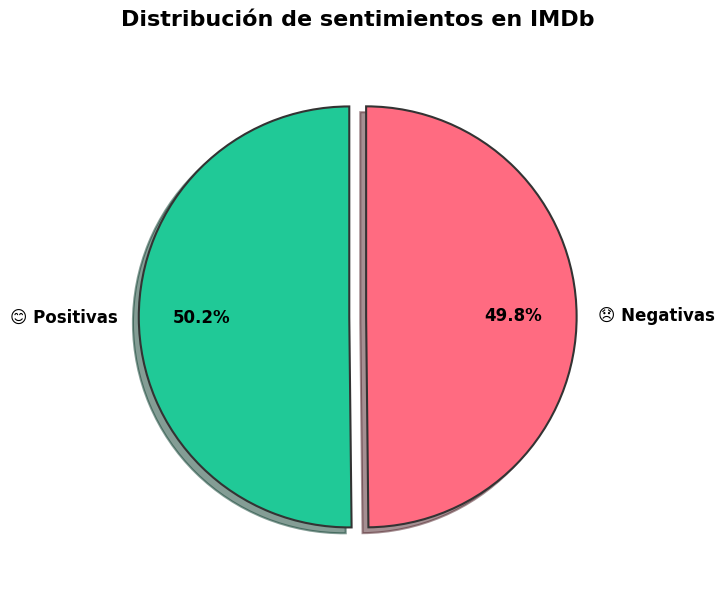

In [ ]:
# Contamos las reseñas de cada grupo
cantidad_positivas = len(positivas)
cantidad_negativas = len(negativas)

# Creamos el gráfico
plt.figure(figsize=(9, 6)) # establece el tamaño de la figura en pulgadas.

plt.pie(
    [cantidad_positivas, cantidad_negativas],
    labels=["😊 Positivas", "😞 Negativas"],
    colors=["#20C997", "#FF6B81"],  # Turquesa y rosa coral
    autopct="%1.1f%%",             # Porcentaje con un decimal
    startangle=90,                 # Inicio del gráfico
    shadow=True,                   # Añadimos sombra
    explode=(0.04, 0.04),          # Separamos ligeramente los sectores
    pctdistance=0.70,             # Posición de los porcentajes
    textprops={
        'fontsize': 12,   # configura el tamaño y el grosor de las etiquetas.
        'fontweight': 'bold'
    },
    wedgeprops={              # define el color y el grosor del contorno.
        'edgecolor': '#333333',    # Bordes gris oscuro
        'linewidth': 1.5
    }
)

# Añadimos el título y mostramos el gráfico.
plt.title(
    "Distribución de sentimientos en IMDb",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.tight_layout() #ajusta los espacios para evitar que los elementos se recorten.
plt.show()

# 11. ¿En qué rango de longitud se concentran las reseñas?

Investigamos cuántas palabras contienen las reseñas para saber si predominan los comentarios cortos, medios o largos.

Usamos la columna num_palabras creada durante la preparación de los textos. Con pd.cut() agrupamos las reseñas en cuatro intervalos: 0–100, 101–250, 251–500 y más de 500 palabras. Después contamos las reseñas de cada intervalo con value_counts() y las representamos mediante un gráfico de barras.

La tabla describe() también muestra medidas como la media, la mediana (50 %) y los valores mínimo y máximo.

Interpretación: la barra más alta indica el rango en el que se concentra la mayor cantidad de reseñas. El mensaje que aparece al ejecutar el código indica automáticamente cuál es ese intervalo y qué porcentaje representa; así, la conclusión se corresponde con los datos reales.


Resumen de la longitud de las reseñas:


,Número de palabras
count,49599.000000
mean,240.479304
std,179.212282
min,6.000000
25%,129.000000
50%,179.000000
75%,293.000000
max,2498.000000


,Longitud,Cantidad
0,0–100,5825
1,101–250,28120
2,251–500,11280
3,Más de 500,4374


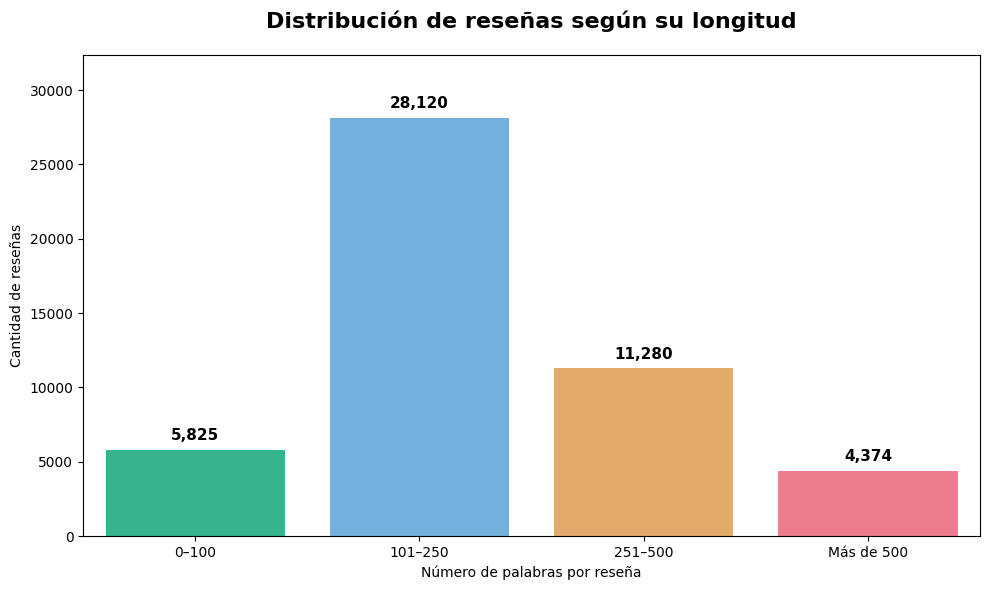

Conclusión: la mayor concentración se encuentra en el intervalo 101–250 palabras (56.7% del total).


In [107]:
import seaborn as sns  # Librería para crear el gráfico de barras.

# La columna num_palabras ya se calculó en la preparación de los textos.
# 1. Agrupamos las reseñas según su longitud.
df["grupo_longitud"] = pd.cut(
    df["num_palabras"],
    bins=[-1, 100, 250, 500, np.inf],
    labels=["0–100", "101–250", "251–500", "Más de 500"]
)

# 3. Mostramos un resumen estadístico.
print("Resumen de la longitud de las reseñas:")

display(
    df["num_palabras"].describe().to_frame("Número de palabras")
)

# 4. Contamos cuántas reseñas hay en cada grupo.
longitud = (
    df["grupo_longitud"]
    .value_counts()
    .sort_index()
    .rename_axis("Longitud")
    .reset_index(name="Cantidad")
)

# Mostramos la tabla de resultados.
display(longitud)

# 5. Creamos el gráfico de barras.
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=longitud,
    x="Longitud",
    y="Cantidad",
    hue="Longitud",
    palette=["#20C997", "#63B3ED", "#F6AD55", "#FF6B81"],
    legend=False
)

# 6. Añadimos la cantidad encima de cada barra.
for barra in ax.patches:

    cantidad = barra.get_height()

    ax.annotate(
        f"{cantidad:,.0f}",
        (
            barra.get_x() + barra.get_width() / 2,
            cantidad
        ),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        xytext=(0, 5),
        textcoords="offset points"
    )

# 7. Añadimos el título y las etiquetas.
plt.title(
    "Distribución de reseñas según su longitud",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Número de palabras por reseña")
plt.ylabel("Cantidad de reseñas")

# Dejamos espacio para los números encima de las barras.
plt.ylim(0, longitud["Cantidad"].max() * 1.15)

# Ajustamos los espacios y mostramos el gráfico.
plt.tight_layout()
plt.show()
# Conclusión automática: identificamos el intervalo con más reseñas.
intervalo_principal = longitud.loc[longitud["Cantidad"].idxmax()]
porcentaje_principal = intervalo_principal["Cantidad"] / longitud["Cantidad"].sum() * 100
print(f"Conclusión: la mayor concentración se encuentra en el intervalo "
      f"{intervalo_principal['Longitud']} palabras "
      f"({porcentaje_principal:.1f}% del total).")

# 12. ¿Qué palabras diferencian las opiniones positivas de las negativas?
**Objetivo:** descubrir qué palabras se utilizan proporcionalmente más en las reseñas positivas y cuáles destacan en las negativas.

Calculamos las frecuencias de ambos sentimientos. CountVectorizer transforma las reseñas en recuentos de palabras y elimina una pequeña lista de palabras comunes (por ejemplo, artículos y preposiciones); conservamos negaciones como «no», «nunca» y «sin» por su importancia para el sentimiento.

Primero contamos las palabras de ambos grupos con el mismo vocabulario. Después calculamos la frecuencia por cada 10.000 palabras contabilizadas en cada grupo, lo que permite comparar los sentimientos aunque tengan distinta cantidad de texto. Filtramos los términos poco frecuentes y obtenemos la diferencia entre ambas frecuencias.

Finalmente, mostramos cinco palabras más características de las positivas y cinco de las negativas mediante un gráfico de barras comparativo.

Cómo interpretar el gráfico: las barras verdes representan la frecuencia en reseñas positivas y las rosas en negativas. Una diferencia mayor entre barras sugiere que la palabra es más característica de uno de los dos sentimientos. Se trata de una comparación de uso de palabras, no de una prueba de causalidad ni de una clasificación perfecta.

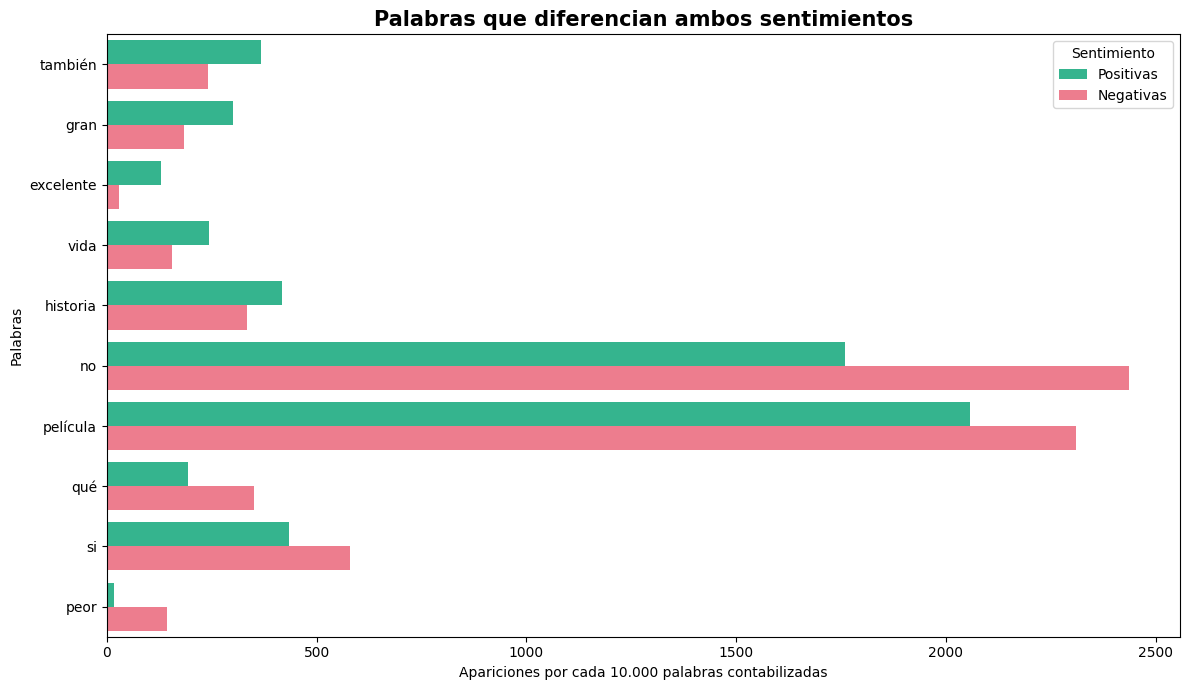

Palabras más características de reseñas positivas: también, gran, excelente, vida, historia
Palabras más características de reseñas negativas: no, película, qué, si, peor


In [110]:
# Importamos la herramienta que convierte textos en recuentos de palabras.
from sklearn.feature_extraction.text import CountVectorizer

# 1. Conservamos las reseñas con sentimiento positivo o negativo y texto disponible.
datos_texto = df.loc[
    df["sentimientos"].isin(["positivo", "negativo"]),
    ["sentimientos", "reseñas_graficos"]
].dropna()

# 2. Excluimos palabras comunes que aportan poca información.
# Mantenemos negaciones importantes como "no", "nunca" y "sin".
palabras_comunes = [
    "el", "la", "los", "las", "un", "una", "unos", "unas",
    "de", "del", "al", "a", "en", "con", "por", "para",
    "que", "es", "son", "y", "o", "se", "su", "sus",
    "lo", "le", "les", "me", "mi", "mis", "te", "tu",
    "más", "muy", "como", "pero", "esta", "este",
    "esto", "esa", "ese", "fue", "ser", "ha", "han",
    "the", "and", "of", "to", "is", "was",
    "with", "for", "this", "that"
]

# 3. Creamos un único vocabulario para los dos sentimientos.
# min_df=5: cada término debe aparecer en al menos cinco reseñas del conjunto.
vectorizador = CountVectorizer(stop_words=palabras_comunes, min_df=5)
matriz_palabras = vectorizador.fit_transform(datos_texto["reseñas_graficos"])
palabras = vectorizador.get_feature_names_out()

# 4. Sumamos las apariciones de cada palabra en las reseñas de cada grupo.
mascara_pos = datos_texto["sentimientos"].eq("positivo").to_numpy()
mascara_neg = datos_texto["sentimientos"].eq("negativo").to_numpy()

comparacion = pd.DataFrame({
    "palabra": palabras,
    "positivas": matriz_palabras[mascara_pos].sum(axis=0).A1,
    "negativas": matriz_palabras[mascara_neg].sum(axis=0).A1
})

# 5. Calculamos los totales para expresar las frecuencias por 10.000 palabras.
total_pos = comparacion["positivas"].sum()
total_neg = comparacion["negativas"].sum()
comparacion["freq_pos"] = comparacion["positivas"] / total_pos * 10000
comparacion["freq_neg"] = comparacion["negativas"] / total_neg * 10000

# 6. Descartamos las palabras que suman menos de 100 apariciones en total.
comparacion = comparacion.loc[
    (comparacion["positivas"] + comparacion["negativas"]) >= 100
].copy()

# 7. La diferencia es positiva si la palabra destaca en reseñas positivas.
# Es negativa si aparece proporcionalmente más en las negativas.
comparacion["diferencia"] = comparacion["freq_pos"] - comparacion["freq_neg"]
mas_positivas = comparacion.nlargest(5, "diferencia")
mas_negativas = comparacion.nsmallest(5, "diferencia")
seleccion = pd.concat([mas_positivas, mas_negativas])

# 8. Convertimos las dos columnas de frecuencia en filas para usar hue en Seaborn.
datos_grafico = seleccion.melt(
    id_vars="palabra",
    value_vars=["freq_pos", "freq_neg"],
    var_name="sentimiento", value_name="frecuencia"
)
datos_grafico["sentimiento"] = datos_grafico["sentimiento"].replace({
    "freq_pos": "Positivas", "freq_neg": "Negativas"
})

# 9. Dibujamos las frecuencias normalizadas de las palabras seleccionadas.
plt.figure(figsize=(12, 7))
sns.barplot(
    data=datos_grafico,
    x="frecuencia", y="palabra",
    order=seleccion["palabra"], hue="sentimiento",
    palette={"Positivas": "#20C997", "Negativas": "#FF6B81"}
)
plt.title("Palabras que diferencian ambos sentimientos", fontsize=15, fontweight="bold")
plt.xlabel("Apariciones por cada 10.000 palabras contabilizadas")
plt.ylabel("Palabras")
plt.legend(title="Sentimiento")
plt.tight_layout()
plt.show()

# 10. Mostramos las palabras que más diferencian a cada grupo.
print("Palabras más características de reseñas positivas:", ", ".join(mas_positivas["palabra"]))
print("Palabras más características de reseñas negativas:", ", ".join(mas_negativas["palabra"]))